# 011 — Model Comparison Figures
# Input:  TFT_results_v3/tft_v3_results.json
#         CNN_LSTM_results_v2/cnn_lstm_v2_results.json
#         nbeats_experiments_v7/exp01_enc72_pred6/test_results.json
#         All three model .npy prediction arrays
# Output: comparison_figures/figure_7_1_horizon_mase_comparison.png (in Thesis Fig. 8.1)
#         comparison_figures/figure_7_2_training_time_vs_mase.png (in Thesis Fig. 8.2)
#         comparison_figures/figure_7_3_combined_snapshot.png (Not used !!!)
 

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Paths ──────────────────────────────────────────────────────────────────────
BASE = "/home/iai-labor/traffic_project"

TFT_JSON    = os.path.join(BASE, "TFT_results_v3",
                           "tft_v3_results.json")
CNN_JSON    = os.path.join(BASE, "CNN_LSTM_results_v2",
                           "cnn_lstm_v2_results.json")
NBEATS_JSON = os.path.join(BASE,
                           "nbeats_experiments_v7",
                           "exp01_enc72_pred6",
                           "test_results.json")

FIGURES_DIR = os.path.join(BASE, "comparison_figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

# ── Load JSON results ──────────────────────────────────────────────────────────
with open(TFT_JSON)    as f: tft    = json.load(f)
with open(CNN_JSON)    as f: cnn    = json.load(f)
with open(NBEATS_JSON) as f: nbeats = json.load(f)

print("Results loaded:")
print(f"  TFT v3    — overall MASE: "
      f"{tft['overall']['MASE']:.4f}")
print(f"  CNN+LSTM  — overall MASE: "
      f"{cnn['overall']['MASE']:.4f}")
print(f"  N-BEATS   — overall MASE: "
      f"{nbeats['overall']['MASE']:.4f}")

Results loaded:
  TFT v3    — overall MASE: 0.5377
  CNN+LSTM  — overall MASE: 0.5767
  N-BEATS   — overall MASE: 0.6133


In [2]:
# ── Verify horizon key format in each file ─────────────────────────────────────
# Different notebooks may have saved keys differently
# Check before extracting

print("TFT horizon keys:")
print(list(tft["horizon_metrics"].keys()))

print("\nCNN+LSTM horizon keys:")
print(list(cnn["horizon_metrics"].keys()))

print("\nN-BEATS horizon keys:")
# N-BEATS may use a different key name — check
nbeats_keys = list(nbeats.keys())
print(f"Top-level keys: {nbeats_keys}")

TFT horizon keys:
['t+1h', 't+2h', 't+3h', 't+4h', 't+5h', 't+6h']

CNN+LSTM horizon keys:
['t+1h', 't+2h', 't+3h', 't+4h', 't+5h', 't+6h']

N-BEATS horizon keys:
Top-level keys: ['model', 'checkpoint', 'encoder_length', 'pred_length', 'best_val_loss', 'best_val_epoch', 'training_epochs', 'weight_decay', 'test_naive_mae', 'val_naive_mae', 'horizon_metrics', 'horizon_naive', 'overall', 'subclass', 'period']


Per-horizon MASE — verification against Chapter 6 tables:
Horizon       TFT   CNN+LSTM    N-BEATS
----------------------------------------
t+1h       0.4522     0.4864     0.4746
t+2h       0.5180     0.5578     0.5780
t+3h       0.5439     0.5860     0.6311
t+4h       0.5595     0.6014     0.6593
t+5h       0.5705     0.6105     0.6629
t+6h       0.5820     0.6183     0.6737

Spreads (t+6h − t+1h):
  TFT:      0.130
  CNN+LSTM: 0.132
  N-BEATS:  0.199


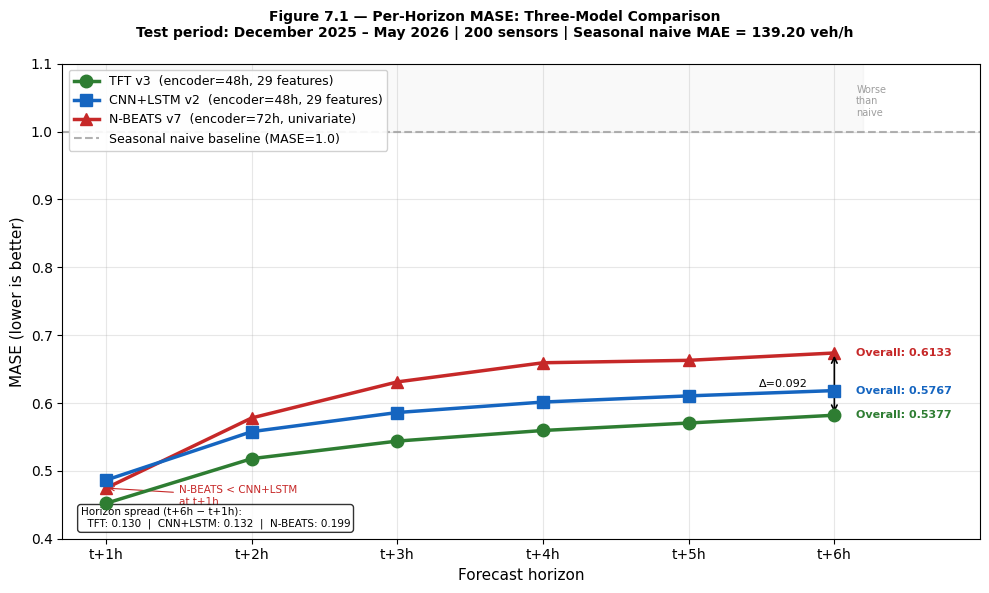

Saved: /home/iai-labor/traffic_project/comparison_figures/figure_7_1_horizon_mase_comparison.png


In [3]:
# ── Extract per-horizon MASE ───────────────────────────────────────────────────
horizons     = ["t+1h", "t+2h", "t+3h", "t+4h", "t+5h", "t+6h"]
horizon_nums = [1, 2, 3, 4, 5, 6]

tft_mase    = [tft["horizon_metrics"][h]["MASE"]    for h in horizons]
cnn_mase    = [cnn["horizon_metrics"][h]["MASE"]    for h in horizons]
nbeats_mase = [nbeats["horizon_metrics"][h]["MASE"] for h in horizons]

# Verify against known values
print("Per-horizon MASE — verification against Chapter 6 tables:")
print(f"{'Horizon':<8} {'TFT':>8} {'CNN+LSTM':>10} {'N-BEATS':>10}")
print("-" * 40)
for h, t, c, n in zip(horizons, tft_mase, cnn_mase, nbeats_mase):
    print(f"{h:<8} {t:>8.4f} {c:>10.4f} {n:>10.4f}")

print(f"\nSpreads (t+6h − t+1h):")
print(f"  TFT:      {tft_mase[-1] - tft_mase[0]:.3f}")
print(f"  CNN+LSTM: {cnn_mase[-1] - cnn_mase[0]:.3f}")
print(f"  N-BEATS:  {nbeats_mase[-1] - nbeats_mase[0]:.3f}")

# ── Figure 7.1 ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

# Model colours consistent with evaluation notebooks
COLOR_TFT    = "#2E7D32"   # green
COLOR_CNN    = "#1565C0"   # blue
COLOR_NBEATS = "#C62828"   # red
COLOR_NAIVE  = "#9E9E9E"   # grey

# Plot model lines
ax.plot(horizon_nums, tft_mase,
        color=COLOR_TFT, linewidth=2.5,
        marker="o", markersize=9,
        label=f"TFT v3  (encoder=48h, 29 features)",
        zorder=5)

ax.plot(horizon_nums, cnn_mase,
        color=COLOR_CNN, linewidth=2.5,
        marker="s", markersize=9,
        label=f"CNN+LSTM v2  (encoder=48h, 29 features)",
        zorder=4)

ax.plot(horizon_nums, nbeats_mase,
        color=COLOR_NBEATS, linewidth=2.5,
        marker="^", markersize=9,
        label=f"N-BEATS v7  (encoder=72h, univariate)",
        zorder=3)

# Naive baseline
ax.axhline(y=1.0, color=COLOR_NAIVE, linewidth=1.5,
           linestyle="--", alpha=0.8,
           label="Seasonal naive baseline (MASE=1.0)")

# MASE=1.0 fill — above this line = worse than naive
ax.fill_between([0.8, 6.2], [1.0, 1.0], [1.15, 1.15],
                color=COLOR_NAIVE, alpha=0.06)
ax.text(6.15, 1.02, "Worse\nthan\nnaive",
        fontsize=7, color=COLOR_NAIVE, va="bottom", ha="left")

# Annotate overall MASE values on the right side
ax.annotate(f"Overall: {tft['overall']['MASE']:.4f}",
            xy=(6, tft_mase[-1]),
            xytext=(6.15, tft_mase[-1]),
            fontsize=8, color=COLOR_TFT, va="center",
            fontweight="bold")
ax.annotate(f"Overall: {cnn['overall']['MASE']:.4f}",
            xy=(6, cnn_mase[-1]),
            xytext=(6.15, cnn_mase[-1]),
            fontsize=8, color=COLOR_CNN, va="center",
            fontweight="bold")
ax.annotate(f"Overall: {nbeats['overall']['MASE']:.4f}",
            xy=(6, nbeats_mase[-1]),
            xytext=(6.15, nbeats_mase[-1]),
            fontsize=8, color=COLOR_NBEATS, va="center",
            fontweight="bold")

# Annotate the spread difference
ax.annotate("",
            xy=(6.0, nbeats_mase[-1]),
            xytext=(6.0, tft_mase[-1]),
            arrowprops=dict(
                arrowstyle="<->",
                color="black",
                lw=1.2
            ))
ax.text(5.82, (nbeats_mase[-1] + tft_mase[-1]) / 2,
        f"Δ={nbeats_mase[-1]-tft_mase[-1]:.3f}",
        fontsize=8, ha="right", va="center", color="black")

# t+1h annotation — N-BEATS beats CNN+LSTM
ax.annotate("N-BEATS < CNN+LSTM\nat t+1h",
            xy=(1, nbeats_mase[0]),
            xytext=(1.5, nbeats_mase[0] - 0.025),
            fontsize=7.5, color="#C62828",
            ha="left",
            arrowprops=dict(arrowstyle="->",
                            color="#C62828", lw=0.8))

# Axes formatting
ax.set_xlabel("Forecast horizon", fontsize=11)
ax.set_ylabel("MASE (lower is better)", fontsize=11)
ax.set_xticks(horizon_nums)
ax.set_xticklabels(horizons, fontsize=10)
ax.set_xlim(0.7, 7.0)
ax.set_ylim(0.40, 1.10)
ax.grid(True, alpha=0.3)

# Spread annotation in legend area
spread_text = (
    f"Horizon spread (t+6h − t+1h):\n"
    f"  TFT: {tft_mase[-1]-tft_mase[0]:.3f}  |  "
    f"CNN+LSTM: {cnn_mase[-1]-cnn_mase[0]:.3f}  |  "
    f"N-BEATS: {nbeats_mase[-1]-nbeats_mase[0]:.3f}"
)
ax.text(0.02, 0.02, spread_text,
        transform=ax.transAxes,
        fontsize=7.5, va="bottom",
        bbox=dict(boxstyle="round,pad=0.3",
                  facecolor="white", alpha=0.8))

ax.legend(fontsize=9, loc="upper left",
          framealpha=0.9)

fig.suptitle(
    "Figure 7.1 — Per-Horizon MASE: Three-Model Comparison\n"
    "Test period: December 2025 – May 2026 | "
    "200 sensors | Seasonal naive MAE = 139.20 veh/h",
    fontsize=10, fontweight="bold"
)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "figure_7_1_horizon_mase_comparison.png")
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

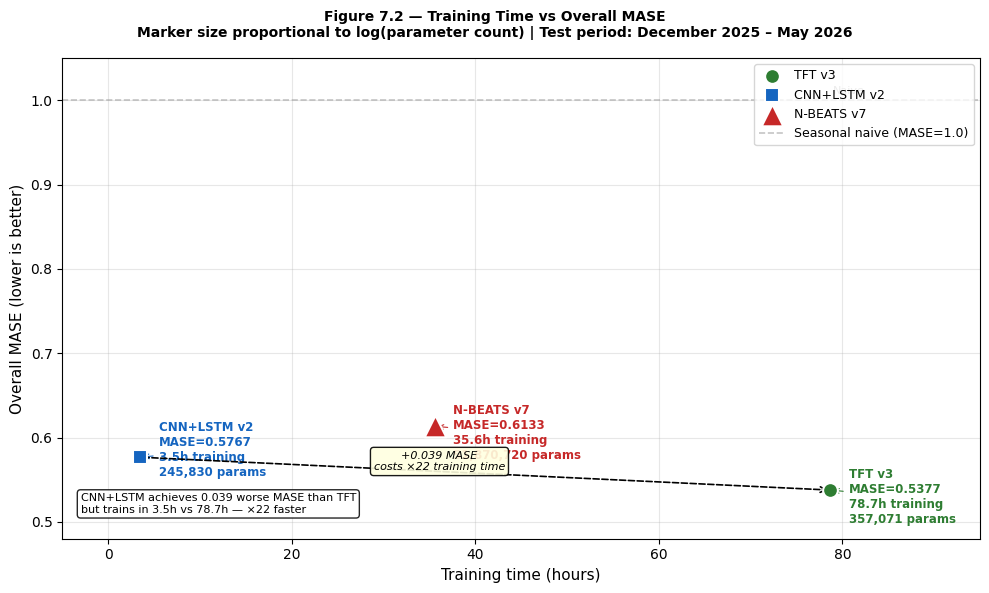

Saved: /home/iai-labor/traffic_project/comparison_figures/figure_7_2_training_time_vs_mase.png

All Chapter 7 figures:
  ✓  figure_7_1_horizon_mase_comparison.png
  ✓  figure_7_2_training_time_vs_mase.png


In [4]:
# ── Model data ─────────────────────────────────────────────────────────────────
# Confirmed test results — December 2025 to May 2026
models = {
    "TFT v3": {
        "mase":          0.5377,
        "training_hours": 78.7,
        "params":         357_071,
        "color":          COLOR_TFT,
        "marker":         "o",
        "encoder":        "48h",
        "features":       "29 features",
    },
    "CNN+LSTM v2": {
        "mase":          0.5767,
        "training_hours": 3.5,
        "params":         245_830,
        "color":          COLOR_CNN,
        "marker":         "s",
        "encoder":        "48h",
        "features":       "29 features",
    },
    "N-BEATS v7": {
        "mase":          0.6133,
        "training_hours": 35.6,
        "params":         51_870_720,
        "color":          COLOR_NBEATS,
        "marker":         "^",
        "encoder":        "72h",
        "features":       "univariate",
    },
}

# ── Figure 7.2 ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

for name, m in models.items():
    # Marker size proportional to parameter count (log scale)
    # Gives visual sense of model complexity
    marker_size = 80 + 60 * (np.log10(m["params"]) - 5)

    ax.scatter(
        m["training_hours"], m["mase"],
        color   = m["color"],
        marker  = m["marker"],
        s       = marker_size,
        zorder  = 5,
        label   = name,
        edgecolors = "white",
        linewidths = 1.5,
    )

    # Label each point
    offset_x = {
        "TFT v3":      2.0,
        "CNN+LSTM v2": 2.0,
        "N-BEATS v7":  2.0,
    }
    offset_y = {
        "TFT v3":      -0.008,
        "CNN+LSTM v2":  0.008,
        "N-BEATS v7":  -0.008,
    }

    ax.annotate(
        f"{name}\n"
        f"MASE={m['mase']:.4f}\n"
        f"{m['training_hours']}h training\n"
        f"{m['params']:,} params",
        xy     = (m["training_hours"], m["mase"]),
        xytext = (m["training_hours"] + offset_x[name],
                  m["mase"]          + offset_y[name]),
        fontsize   = 8.5,
        color      = m["color"],
        fontweight = "bold",
        va="center",
        arrowprops = dict(
            arrowstyle = "->",
            color      = m["color"],
            lw         = 0.8,
        )
    )

# ── Efficiency annotation ──────────────────────────────────────────────────────
# Arrow from CNN+LSTM to TFT showing the trade-off
ax.annotate(
    "",
    xy     = (models["TFT v3"]["training_hours"],
              models["TFT v3"]["mase"]),
    xytext = (models["CNN+LSTM v2"]["training_hours"],
              models["CNN+LSTM v2"]["mase"]),
    arrowprops = dict(
        arrowstyle = "->",
        color      = "black",
        lw         = 1.2,
        linestyle  = "dashed",
    )
)

# Label the trade-off
mid_x = (models["TFT v3"]["training_hours"] +
          models["CNN+LSTM v2"]["training_hours"]) / 2
mid_y = (models["TFT v3"]["mase"] +
          models["CNN+LSTM v2"]["mase"]) / 2

mase_gain  = models["CNN+LSTM v2"]["mase"] - models["TFT v3"]["mase"]
time_cost  = models["TFT v3"]["training_hours"] - \
             models["CNN+LSTM v2"]["training_hours"]
time_ratio = models["TFT v3"]["training_hours"] / \
             models["CNN+LSTM v2"]["training_hours"]

ax.text(
    mid_x - 5, mid_y + 0.004,
    f"+{mase_gain:.3f} MASE\ncosts ×{time_ratio:.0f} training time",
    fontsize = 8,
    ha       = "center",
    color    = "black",
    style    = "italic",
    bbox     = dict(boxstyle="round,pad=0.3",
                    facecolor="lightyellow",
                    alpha=0.9)
)

# ── Naive baseline reference ───────────────────────────────────────────────────
ax.axhline(y=1.0, color=COLOR_NAIVE, linewidth=1.2,
           linestyle="--", alpha=0.6,
           label="Seasonal naive (MASE=1.0)")
ax.text(79, 1.005, "Naive", fontsize=8,
        color=COLOR_NAIVE, va="bottom")

# ── Axes formatting ────────────────────────────────────────────────────────────
ax.set_xlabel("Training time (hours)", fontsize=11)
ax.set_ylabel("Overall MASE (lower is better)", fontsize=11)
ax.set_xlim(-5, 95)
ax.set_ylim(0.48, 1.05)
ax.grid(True, alpha=0.3)

# Summary box
summary = (
    f"CNN+LSTM achieves {mase_gain:.3f} worse MASE than TFT\n"
    f"but trains in {models['CNN+LSTM v2']['training_hours']}h "
    f"vs {models['TFT v3']['training_hours']}h — "
    f"×{time_ratio:.0f} faster"
)
ax.text(0.02, 0.05, summary,
        transform   = ax.transAxes,
        fontsize    = 8,
        va          = "bottom",
        bbox        = dict(boxstyle="round,pad=0.3",
                           facecolor="white",
                           alpha=0.85))

ax.legend(fontsize=9, loc="upper right")

fig.suptitle(
    "Figure 7.2 — Training Time vs Overall MASE\n"
    "Marker size proportional to log(parameter count) | "
    "Test period: December 2025 – May 2026",
    fontsize=10, fontweight="bold"
)

plt.tight_layout()
fig_path = os.path.join(
    FIGURES_DIR, "figure_7_2_training_time_vs_mase.png"
)
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

# ── Final checklist ────────────────────────────────────────────────────────────
print("\nAll Chapter 7 figures:")
for fname in [
    "figure_7_1_horizon_mase_comparison.png",
    "figure_7_2_training_time_vs_mase.png",
]:
    fpath  = os.path.join(FIGURES_DIR, fname)
    exists = "✓" if os.path.exists(fpath) else "✗ MISSING"
    print(f"  {exists}  {fname}")

In [5]:
import duckdb
import pandas as pd

# ── Load prediction arrays ─────────────────────────────────────────────────────
print("Loading prediction arrays...")

# TFT v3
tft_pred   = np.load(os.path.join(BASE, "TFT_results_v3",
                                   "tft_v3_pred_veh.npy"))
tft_actual = np.load(os.path.join(BASE, "TFT_results_v3",
                                   "tft_v3_actual_veh.npy"))
tft_sens   = np.load(os.path.join(BASE, "TFT_results_v3",
                                   "tft_v3_sensor_arr.npy"))
tft_ts     = np.load(os.path.join(BASE, "TFT_results_v3",
                                   "tft_v3_ts_arr.npy"))

# CNN+LSTM v2
cnn_pred   = np.load(os.path.join(BASE, "CNN_LSTM_results_v2",
                                   "cnn_lstm_pred_veh.npy"))
cnn_actual = np.load(os.path.join(BASE, "CNN_LSTM_results_v2",
                                   "cnn_lstm_actual_veh.npy"))
cnn_sens   = np.load(os.path.join(BASE, "CNN_LSTM_results_v2",
                                   "cnn_lstm_sensor_arr.npy"))
cnn_ts     = np.load(os.path.join(BASE, "CNN_LSTM_results_v2",
                                   "cnn_lstm_ts_matrix.npy"))

# N-BEATS v7
nb_dir     = os.path.join(BASE,
                           "nbeats_experiments_v7",
                           "exp01_enc72_pred6")
nb_pred    = np.load(os.path.join(nb_dir, "pred_veh.npy"))
nb_actual  = np.load(os.path.join(nb_dir, "actual_veh.npy"))
nb_sens    = np.load(os.path.join(nb_dir, "sensor_arr.npy"))
nb_ts      = np.load(os.path.join(nb_dir, "ts_arr.npy"))

print(f"TFT:      pred={tft_pred.shape}  actual={tft_actual.shape}")
print(f"CNN+LSTM: pred={cnn_pred.shape}  actual={cnn_actual.shape}")
print(f"N-BEATS:  pred={nb_pred.shape}   actual={nb_actual.shape}")

# ── Load sensor data — compute time_idx after loading ─────────────────────────
# time_idx is not stored in parquet — computed from DATETIME
print("\nLoading sensor data for encoder history...")

FEATURES_PATH     = os.path.join(BASE, "traffic_features_v3.parquet")
TARGET_SENSOR     = 3395
TARGET_SENSOR_STR = str(TARGET_SENSOR)

con = duckdb.connect()
df_sensor = con.sql(f"""
    SELECT DATETIME, target
    FROM read_parquet('{FEATURES_PATH}')
    WHERE SENSOR_ID = {TARGET_SENSOR}
      AND target IS NOT NULL
    ORDER BY DATETIME
""").df()

df_sensor["DATETIME"] = pd.to_datetime(df_sensor["DATETIME"])
df_sensor             = df_sensor.sort_values("DATETIME").reset_index(drop=True)

# Compute time_idx — hours from the global time origin
time_origin          = df_sensor["DATETIME"].min()
df_sensor["time_idx"] = (
    (df_sensor["DATETIME"] - time_origin)
    .dt.total_seconds()
    .div(3600)
    .round()
    .astype(int)
)
df_sensor = df_sensor.set_index("time_idx").sort_index()

print(f"Sensor {TARGET_SENSOR}: {len(df_sensor):,} observations")
print(f"Date range: {df_sensor['DATETIME'].min()} "
      f"– {df_sensor['DATETIME'].max()}")

# ── Sensor stats ───────────────────────────────────────────────────────────────
sensor_stats = pd.read_csv(
    os.path.join(BASE, "TFT_results_v3", "sensor_stats.csv"),
    index_col="SENSOR_ID"
)
mu_s    = float(sensor_stats.loc[TARGET_SENSOR, "mu"])
sigma_s = float(sensor_stats.loc[TARGET_SENSOR, "sigma"])
print(f"\nSensor {TARGET_SENSOR} stats: "
      f"μ={mu_s:.1f}, σ={sigma_s:.1f} veh/h")

Loading prediction arrays...
TFT:      pred=(868000, 6)  actual=(868000, 6)
CNN+LSTM: pred=(868000, 6)  actual=(868000, 6)
N-BEATS:  pred=(868000, 6)   actual=(868000, 6)

Loading sensor data for encoder history...
Sensor 3395: 29,928 observations
Date range: 2023-01-01 00:00:00 – 2026-05-31 23:00:00

Sensor 3395 stats: μ=282.8, σ=186.6 veh/h


Sensor 3395 windows:
  TFT:      4,362
  CNN+LSTM: 4,362
  N-BEATS:  4,362

Common decoder-start timesteps: 4,361

Chosen forecast origin: Monday 01 Dec 2025 14:00
  time_idx of t+1h: 25574

Actual values (veh/h): [np.float64(454.2), np.float64(437.5), np.float64(539.7), np.float64(526.0), np.float64(484.8), np.float64(471.0)]
TFT preds  (veh/h):   [np.float64(432.1), np.float64(456.7), np.float64(483.5), np.float64(515.3), np.float64(503.6), np.float64(443.0)]
CNN preds  (veh/h):   [np.float64(421.6), np.float64(445.9), np.float64(497.9), np.float64(514.3), np.float64(484.1), np.float64(422.8)]
N-BEATS    (veh/h):   [np.float64(454.1), np.float64(462.6), np.float64(469.1), np.float64(491.7), np.float64(518.5), np.float64(515.6)]

History lengths: 48h=48 | 72h=72


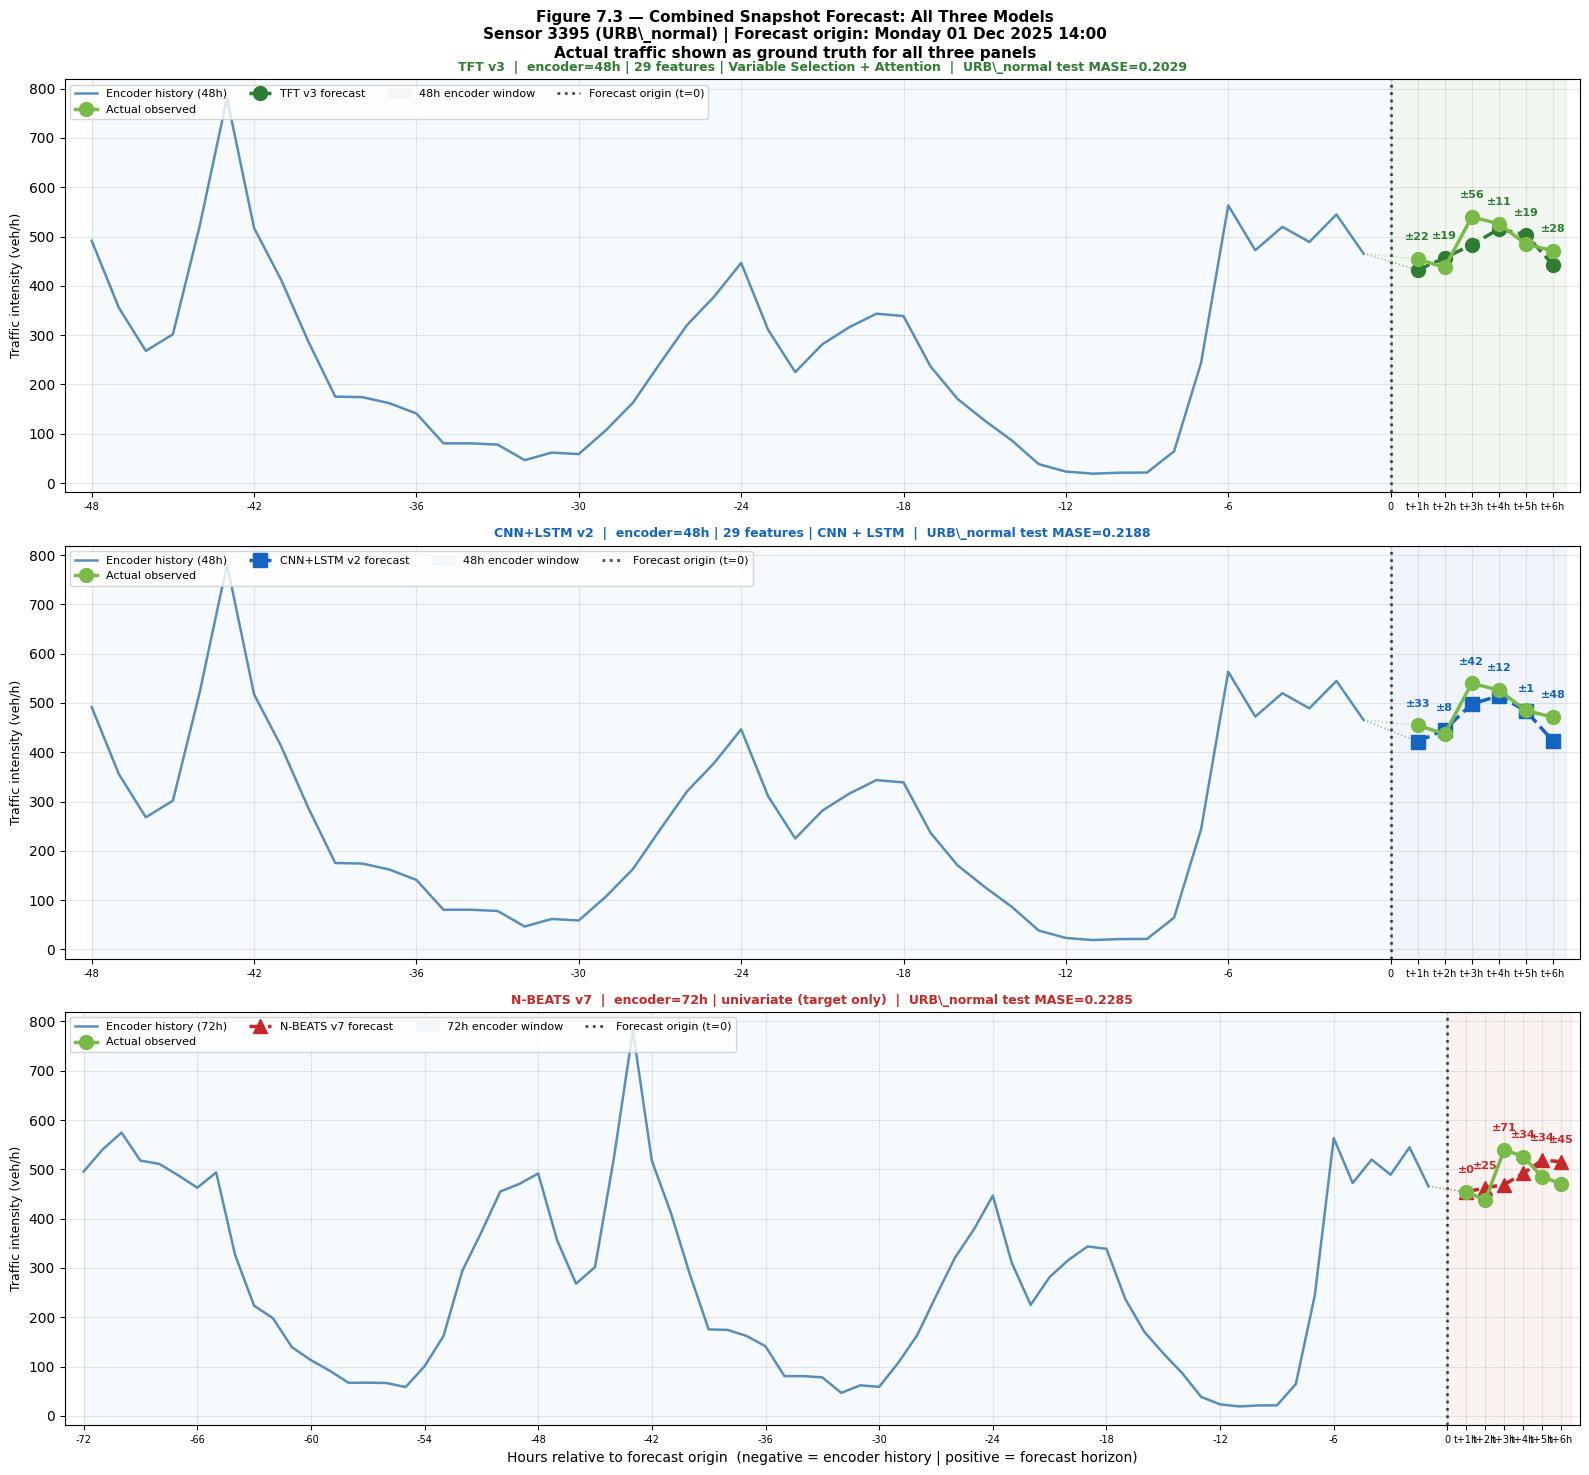

Saved: /home/iai-labor/traffic_project/comparison_figures/figure_7_3_combined_snapshot.png

Snapshot forecast summary — Sensor 3395 | Mon 01 Dec 2025 14:00:
Horizon    Actual      TFT      CNN  N-BEATS
---------------------------------------------
t+1h        454.2    432.1    421.6    454.1
t+2h        437.5    456.7    445.9    462.6
t+3h        539.7    483.5    497.9    469.1
t+4h        526.0    515.3    514.3    491.7
t+5h        484.8    503.6    484.1    518.5
t+6h        471.0    443.0    422.8    515.6

All Chapter 7 figures:
  ✓  figure_7_1_horizon_mase_comparison.png
  ✓  figure_7_2_training_time_vs_mase.png
  ✓  figure_7_3_combined_snapshot.png


In [6]:
# ── Find a common prediction window ───────────────────────────────────────────
# Find common prediction window for sensor 3395 across all three models

# TFT ts_arr shape: (windows, 6) — each row is 6 decoder timesteps
# CNN ts_arr shape: (windows, 6) — same
# N-BEATS ts_arr shape: (windows, 6) — same

# Find sensor 3395 windows in TFT
tft_mask  = tft_sens == TARGET_SENSOR_STR
tft_idx   = np.where(tft_mask)[0]

cnn_mask  = cnn_sens == TARGET_SENSOR_STR
cnn_idx   = np.where(cnn_mask)[0]

nb_mask   = nb_sens == TARGET_SENSOR_STR
nb_idx    = np.where(nb_mask)[0]

print(f"Sensor {TARGET_SENSOR} windows:")
print(f"  TFT:      {len(tft_idx):,}")
print(f"  CNN+LSTM: {len(cnn_idx):,}")
print(f"  N-BEATS:  {len(nb_idx):,}")

# Decoder start timestep for each model (t+1h position)
tft_t1  = tft_ts[tft_idx, 0]   # first decoder step
cnn_t1  = cnn_ts[cnn_idx, 0]
nb_t1   = nb_ts[nb_idx, 0]

# Find timesteps common to all three
common_t1 = np.intersect1d(np.intersect1d(tft_t1, cnn_t1), nb_t1)
print(f"\nCommon decoder-start timesteps: {len(common_t1):,}")

# Pick a weekday afternoon window in the test period
# val_end_idx = 25559 (confirmed from earlier)
VAL_END = 25559

# Filter to test period and weekday afternoon (14-18h)
test_common = common_t1[common_t1 > VAL_END]

chosen_t1 = None
for t in test_common:
    dt = time_origin + pd.Timedelta(hours=int(t))
    if dt.dayofweek < 5 and 14 <= dt.hour <= 18:
        # Check actual traffic is meaningful (not near zero)
        tft_pos  = tft_idx[tft_t1  == t][0]
        if tft_actual[tft_pos].mean() > 150:
            chosen_t1 = t
            chosen_dt = dt
            break

if chosen_t1 is None:
    chosen_t1 = test_common[len(test_common)//2]
    chosen_dt = time_origin + pd.Timedelta(hours=int(chosen_t1))

print(f"\nChosen forecast origin: {chosen_dt.strftime('%A %d %b %Y %H:%M')}")
print(f"  time_idx of t+1h: {chosen_t1}")

# Get prediction row indices for each model
tft_row = tft_idx[tft_t1  == chosen_t1][0]
cnn_row = cnn_idx[cnn_t1  == chosen_t1][0]
nb_row  = nb_idx[nb_t1   == chosen_t1][0]

# Actual values — use TFT actuals (all three should agree)
actual_vals = tft_actual[tft_row]   # (6,)

# Predictions per model
tft_preds = tft_pred[tft_row]       # (6,)
cnn_preds = cnn_pred[cnn_row]       # (6,)
nb_preds  = nb_pred[nb_row]         # (6,)

print(f"\nActual values (veh/h): "
      f"{[round(v,1) for v in actual_vals]}")
print(f"TFT preds  (veh/h):   "
      f"{[round(v,1) for v in tft_preds]}")
print(f"CNN preds  (veh/h):   "
      f"{[round(v,1) for v in cnn_preds]}")
print(f"N-BEATS    (veh/h):   "
      f"{[round(v,1) for v in nb_preds]}")

# ── Get encoder history for each model ────────────────────────────────────────
# TFT and CNN: 48h encoder
# N-BEATS: 72h encoder
FORECAST_ORIGIN_T = chosen_t1 - 1   # last encoder timestep

# 48h history (for TFT and CNN+LSTM)
t_start_48 = FORECAST_ORIGIN_T - 47
t_end_48   = FORECAST_ORIGIN_T

# 72h history (for N-BEATS)
t_start_72 = FORECAST_ORIGIN_T - 71
t_end_72   = FORECAST_ORIGIN_T

history_48 = df_sensor.loc[
    df_sensor.index.isin(range(t_start_48, t_end_48 + 1)),
    "target"
].values

history_72 = df_sensor.loc[
    df_sensor.index.isin(range(t_start_72, t_end_72 + 1)),
    "target"
].values

print(f"\nHistory lengths: 48h={len(history_48)} | 72h={len(history_72)}")

# Future timesteps
future_x = np.array([1, 2, 3, 4, 5, 6])

# ── Figure ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(16, 15), sharex=False)
fig.suptitle(
    f"Figure 7.3 — Combined Snapshot Forecast: All Three Models\n"
    f"Sensor {TARGET_SENSOR} (URB\\_normal) | "
    f"Forecast origin: {chosen_dt.strftime('%A %d %b %Y %H:%M')}\n"
    f"Actual traffic shown as ground truth for all three panels",
    fontsize=11, fontweight="bold"
)

model_configs = [
    {
        "name":    "TFT v3",
        "preds":   tft_preds,
        "color":   COLOR_TFT,
        "marker":  "o",
        "enc_len": 48,
        "history": history_48,
        "mase":    tft["subclass"]["URB_normal"]["MASE"],
        "info":    "encoder=48h | 29 features | Variable Selection + Attention",
    },
    {
        "name":    "CNN+LSTM v2",
        "preds":   cnn_preds,
        "color":   COLOR_CNN,
        "marker":  "s",
        "enc_len": 48,
        "history": history_48,
        "mase":    cnn["subclass"]["URB_normal"]["MASE"],
        "info":    "encoder=48h | 29 features | CNN + LSTM",
    },
    {
        "name":    "N-BEATS v7",
        "preds":   nb_preds,
        "color":   COLOR_NBEATS,
        "marker":  "^",
        "enc_len": 72,
        "history": history_72,
        "mase":    nbeats["subclass"]["URB_normal"]["MASE"],
        "info":    "encoder=72h | univariate (target only)",
    },
]

for ax, cfg in zip(axes, model_configs):
    enc_len = cfg["enc_len"]
    history = cfg["history"]
    preds   = cfg["preds"]
    color   = cfg["color"]

    # Pad history if needed
    if len(history) < enc_len:
        history = np.pad(history, (enc_len - len(history), 0),
                         constant_values=np.nan)

    history_x = np.arange(-enc_len, 0)  # e.g. -48..−1 or -72..−1

    # ── History line ───────────────────────────────────────────────
    ax.plot(history_x, history,
            color="steelblue", linewidth=1.8,
            alpha=0.9, label=f"Encoder history ({enc_len}h)",
            zorder=3)

    # ── Actual future values ───────────────────────────────────────
    ax.plot(future_x, actual_vals,
            color="#7aba49", linewidth=2.5,
            marker="o", markersize=10,
            label="Actual observed", zorder=6)

    # ── Model predictions ──────────────────────────────────────────
    ax.plot(future_x, preds,
            color=color, linewidth=2.5,
            marker=cfg["marker"], markersize=10,
            linestyle="--",
            label=f"{cfg['name']} forecast", zorder=5)

    # ── Connect history to predictions ─────────────────────────────
    ax.plot([-1, 1], [history[-1], preds[0]],
            color=color, linewidth=1.0,
            linestyle=":", alpha=0.5, zorder=3)
    ax.plot([-1, 1], [history[-1], actual_vals[0]],
            color="#7aba49", linewidth=1.0,
            linestyle=":", alpha=0.5, zorder=3)

    # ── Shaded regions ─────────────────────────────────────────────
    ax.axvspan(-enc_len, 0, alpha=0.04, color="steelblue",
               label=f"{enc_len}h encoder window")
    ax.axvspan(0, 6.5, alpha=0.06, color=color)

    # ── Forecast origin line ───────────────────────────────────────
    ax.axvline(x=0, color="black", linestyle=":",
               linewidth=2.0, alpha=0.7,
               label="Forecast origin (t=0)")

    # ── Error annotations ──────────────────────────────────────────
    y_range = max(history[~np.isnan(history)].max(),
                  actual_vals.max(),
                  preds.max()) - \
              min(history[~np.isnan(history)].min(),
                  actual_vals.min(),
                  preds.min())

    for h_idx, fx in enumerate(future_x):
        err  = abs(preds[h_idx] - actual_vals[h_idx])
        ypos = max(preds[h_idx], actual_vals[h_idx]) + y_range * 0.05
        ax.annotate(
            f"±{err:.0f}",
            xy=(fx, ypos),
            fontsize=8, color=color,
            ha="center", fontweight="bold"
        )

    # ── X axis ─────────────────────────────────────────────────────
    if enc_len == 48:
        xtick_hist   = list(range(-48, 0, 6))
        xtick_labels = [str(h) for h in xtick_hist] + \
                       ["0", "t+1h", "t+2h", "t+3h",
                        "t+4h", "t+5h", "t+6h"]
    else:
        xtick_hist   = list(range(-72, 0, 6))
        xtick_labels = [str(h) for h in xtick_hist] + \
                       ["0", "t+1h", "t+2h", "t+3h",
                        "t+4h", "t+5h", "t+6h"]

    ax.set_xticks(xtick_hist + [0, 1, 2, 3, 4, 5, 6])
    ax.set_xticklabels(xtick_labels, fontsize=7)
    ax.set_xlim(-enc_len - 1, 7)

    # ── Labels and title ───────────────────────────────────────────
    ax.set_ylabel("Traffic intensity (veh/h)", fontsize=9)
    ax.set_title(
        f"{cfg['name']}  |  {cfg['info']}  |  "
        f"URB\\_normal test MASE={cfg['mase']:.4f}",
        fontsize=9, fontweight="bold", color=color
    )
    ax.legend(loc="upper left", fontsize=8, ncol=4)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel(
    "Hours relative to forecast origin  "
    "(negative = encoder history | positive = forecast horizon)",
    fontsize=10
)

plt.tight_layout()
fig_path = os.path.join(
    FIGURES_DIR, "figure_7_3_combined_snapshot.png"
)
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved: {fig_path}")

# ── Summary table ──────────────────────────────────────────────────────────────
print(f"\nSnapshot forecast summary — Sensor {TARGET_SENSOR} | "
      f"{chosen_dt.strftime('%a %d %b %Y %H:%M')}:")
print(f"{'Horizon':<8} {'Actual':>8} {'TFT':>8} "
      f"{'CNN':>8} {'N-BEATS':>8}")
print("-" * 45)
for i, h in enumerate(["t+1h","t+2h","t+3h",
                        "t+4h","t+5h","t+6h"]):
    print(f"{h:<8} {actual_vals[i]:>8.1f} "
          f"{tft_preds[i]:>8.1f} "
          f"{cnn_preds[i]:>8.1f} "
          f"{nb_preds[i]:>8.1f}")

# ── Final checklist ────────────────────────────────────────────────────────────
print("\nAll Chapter 7 figures:")
for fname in [
    "figure_7_1_horizon_mase_comparison.png",
    "figure_7_2_training_time_vs_mase.png",
    "figure_7_3_combined_snapshot.png",
]:
    fpath  = os.path.join(FIGURES_DIR, fname)
    exists = "✓" if os.path.exists(fpath) else "✗ MISSING"
    print(f"  {exists}  {fname}")